In [ ]:
import pathlib

import marimo as mo
from matplotlib import colors as mpl_colors
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from teeplot import teeplot as tp
from watermark import watermark

from pylib.theory._calc_mutator_fixprob_closed import (
    calc_mutator_fixprob_closed,
)
from pylib.theory._resimulate_wellmixed import resimulate_wellmixed

In [ ]:
mo.md(
    f"""
```Text
{watermark(
    current_date=True,
    iso8601=True,
    machine=True,
    updated=True,
    python=True,
    iversions=True,
    globals_=globals(),
)}
```
"""
)

```Text
Last updated: 2026-11-26T12:10:21.873175+00:00

Python implementation: CPython
Python version       : 3.10.22
IPython version      : 7.31.1

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 7.0.0-1014-aws
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

numpy     : 2.1.2
teeplot   : 1.2.0
marimo    : 0.23.2
matplotlib: 3.9.2
pandas    : 2.2.3

```

In [ ]:
teeplot_subdir = pathlib.Path(__file__).stem
teeplot_subdir

'theory-hypermutator-advantage'

# Hypermutator advantage under limited adaptive potential

Figure 1 of [Raynes et al. (2018)](https://doi.org/10.1073/pnas.1715996115) shows that the sign of selection on a mutator allele depends on population size $N$: mutators are disfavored in small populations and favored in large ones.

Here we draw the counterpart for this project's 50/50 competitions, and add curves for limited adaptive potential, where only one or two beneficial mutations are available.
Hypermutator advantage is $2 P_\mathrm{fix} - 1$: $+1$ if mutators always fix, $0$ for an even outcome (the neutral expectation), and $-1$ if nonmutators always fix.

Curves are the analytic approximation (`calc_mutator_fixprob_closed`),

$$P_\mathrm{fix} = P_\mathrm{escape}(N) \, [1 - P_\mathrm{catchup}(N, K)],$$

with $P_\mathrm{catchup} = 0$ for unlimited adaptive potential (after Raynes et al.).
Points are a class-count resimulation of the well-mixed model (`resimulate_wellmixed`), with 40 available beneficial mutations standing in for unlimited.

Limited adaptive potential leaves small populations untouched but disfavors mutators again in large ones.

In [ ]:
model_N = np.geomspace(8, 1e8, 500)
model_advantage = {
    K: np.array(
        [2 * calc_mutator_fixprob_closed(N, K) - 1 for N in model_N]
    )
    for K in (np.inf, 1, 2)
}

In [ ]:
df_resim = pd.DataFrame(
    [
        {
            "available beneficial mutations": K,
            "population size": N,
            "hypermutator advantage": 2
            * resimulate_wellmixed(N, K, n_rep=1000, seed=K * N).mean()
            - 1,
        }
        # 40 available beneficial mutations stands in for unlimited
        for K, max_N in ((40, 1e6), (1, 1e8), (2, 1e8))
        for N in np.unique(
            np.round(10 ** np.arange(1.5, 8.01, 0.25)).astype(int)
        ).tolist()
        if N <= max_N
    ]
)
df_resim

,available beneficial mutations,population size,hypermutator advantage
0,40,32,-0.114
1,40,56,-0.204
2,40,100,-0.414
3,40,178,-0.414
4,40,316,-0.348
...,...,...,...
68,2,10000000,-0.514
69,2,17782794,-0.842
70,2,31622777,-0.982
71,2,56234133,-1.000


teeplots/theory-hypermutator-advantage/viz=plot-hypermutator-advantage+ext=.pdf
teeplots/theory-hypermutator-advantage/viz=plot-hypermutator-advantage+ext=.png


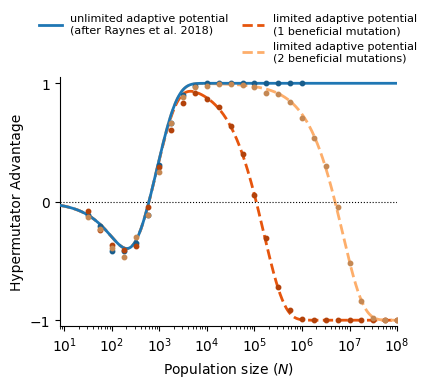

In [ ]:
def plot_hypermutator_advantage() -> plt.Figure:
    fig, ax = plt.subplots(figsize=(4.4, 4))
    handles = []
    for K, resim_K, color, linestyle, label in (
        (
            np.inf,
            40,
            "tab:blue",
            "-",
            "unlimited adaptive potential\n(after Raynes et al. 2018)",
        ),
        (
            1,
            1,
            "#e6550d",
            "--",
            "limited adaptive potential\n(1 beneficial mutation)",
        ),
        (
            2,
            2,
            "#fdae6b",
            "--",
            "limited adaptive potential\n(2 beneficial mutations)",
        ),
    ):
        handles.extend(
            ax.plot(
                model_N,
                model_advantage[K],
                color=color,
                label=label,
                linestyle=linestyle,
                linewidth=2,
                zorder=3 if linestyle == "-" else 2,
            ),
        )
        points = df_resim[
            df_resim["available beneficial mutations"] == resim_K
        ]
        ax.plot(
            points["population size"],
            points["hypermutator advantage"],
            "o",
            # points slightly darker than their line
            color=0.78 * np.array(mpl_colors.to_rgb(color)),
            markersize=3.2,
            zorder=4,
        )
    ax.axhline(0, color="black", linestyle=":", linewidth=0.8)
    ax.set(
        xlabel="Population size ($N$)",
        xlim=(8, 1e8),
        xscale="log",
        ylabel="Hypermutator Advantage",
        ylim=(-1.05, 1.05),
    )
    ax.set_yticks([-1, 0, 1])
    ax.spines[["top", "right"]].set_visible(False)
    # two columns along the top; unlimited entry alone in the first
    blank = plt.Line2D([], [], linestyle="none")
    ax.legend(
        [handles[0], blank, handles[1], handles[2]],
        [
            handles[0].get_label(),
            "",
            *(h.get_label() for h in handles[1:]),
        ],
        bbox_to_anchor=(0.5, 1.02),
        columnspacing=1.2,
        fontsize=8,
        frameon=False,
        loc="lower center",
        ncols=2,
    )
    fig.tight_layout()
    return fig

tp.tee(plot_hypermutator_advantage, teeplot_subdir=teeplot_subdir)